100%|██████████| 170M/170M [02:03<00:00, 1.38MB/s]


Epoch 1 Loss: 1.439
Epoch 2 Loss: 1.1028
Epoch 3 Loss: 0.9598
Epoch 4 Loss: 0.8641
Epoch 5 Loss: 0.7862
Epoch 6 Loss: 0.7206
Epoch 7 Loss: 0.6601
Epoch 8 Loss: 0.5995
Epoch 9 Loss: 0.5456
Epoch 10 Loss: 0.4939
Accuracy on test data: 70.2 %


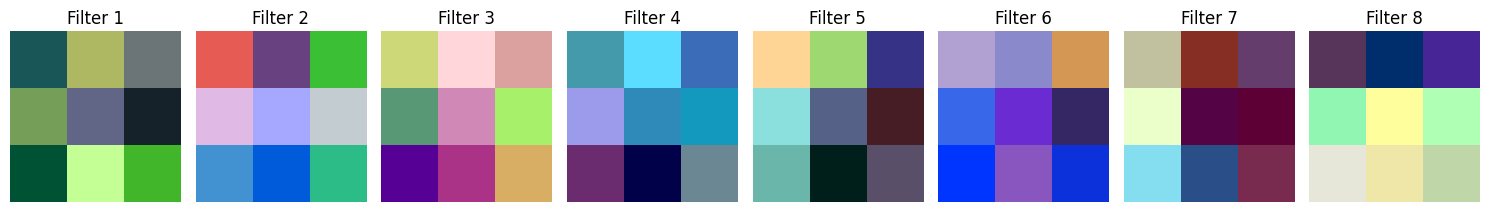

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False
)

classes = trainset.classes


class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)

        self.fc1 = nn.Linear(32 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        x = x.view(-1, 32 * 8 * 8)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SimpleCNN().to(device)

lossfn = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)


for epoch in range(10):
    running_loss = 0.0

    for inputs, labels in trainloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = lossfn(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print("Epoch", epoch + 1, "Loss:", round(running_loss / len(trainloader), 4))


correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = outputs.max(1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print("Accuracy on test data:", round(accuracy, 2), "%")


def visualize_filters(layer, n_filters=8):
    filters = layer.weight.data.clone().cpu()

    fig, axs = plt.subplots(1, n_filters, figsize=(15, 4))

    for i in range(n_filters):
        f = filters[i]

        f = (f - f.min()) / (f.max() - f.min())

        axs[i].imshow(f.permute(1, 2, 0))
        axs[i].axis("off")
        axs[i].set_title("Filter " + str(i + 1))

    plt.tight_layout()
    plt.show()


visualize_filters(model.conv1)